In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_parquet("/Users/yanbernard/MDMI/data/full_trajectories.parquet")
df

,t,x,y,z,vx,vy,vz,v,trajectory_id,is_rocket
0,0.000000,8562.240234,15440.958008,0.000000,572.170959,0.0,313.277649,652.320862,T_000000,False
1,0.100000,8619.413086,15440.958008,31.259428,571.147217,0.0,311.736969,650.683533,T_000000,False
2,0.200000,8676.479492,15440.958008,62.362976,570.089111,0.0,310.179260,649.009033,T_000000,False
3,0.300000,8733.441406,15440.958008,93.311028,569.038940,0.0,308.627686,647.345642,T_000000,False
4,0.400000,8790.297852,15440.958008,124.104202,567.996582,0.0,307.082153,645.693115,T_000000,False
...,...,...,...,...,...,...,...,...,...,...
4273622,95.099998,42143.285156,753.929871,180.788925,160.374954,0.0,-394.112885,425.493927,T_004998,True
4273623,95.199997,42159.316406,753.929871,141.353989,160.189682,0.0,-394.638092,425.910736,T_004998,True
4273624,95.300003,42175.324219,753.929871,101.866646,160.003723,0.0,-395.160461,426.324982,T_004998,True
4273625,95.400002,42191.316406,753.929871,62.327198,159.817062,0.0,-395.679962,426.736603,T_004998,True


839 rows | rocket: True | duration: 83.8 s


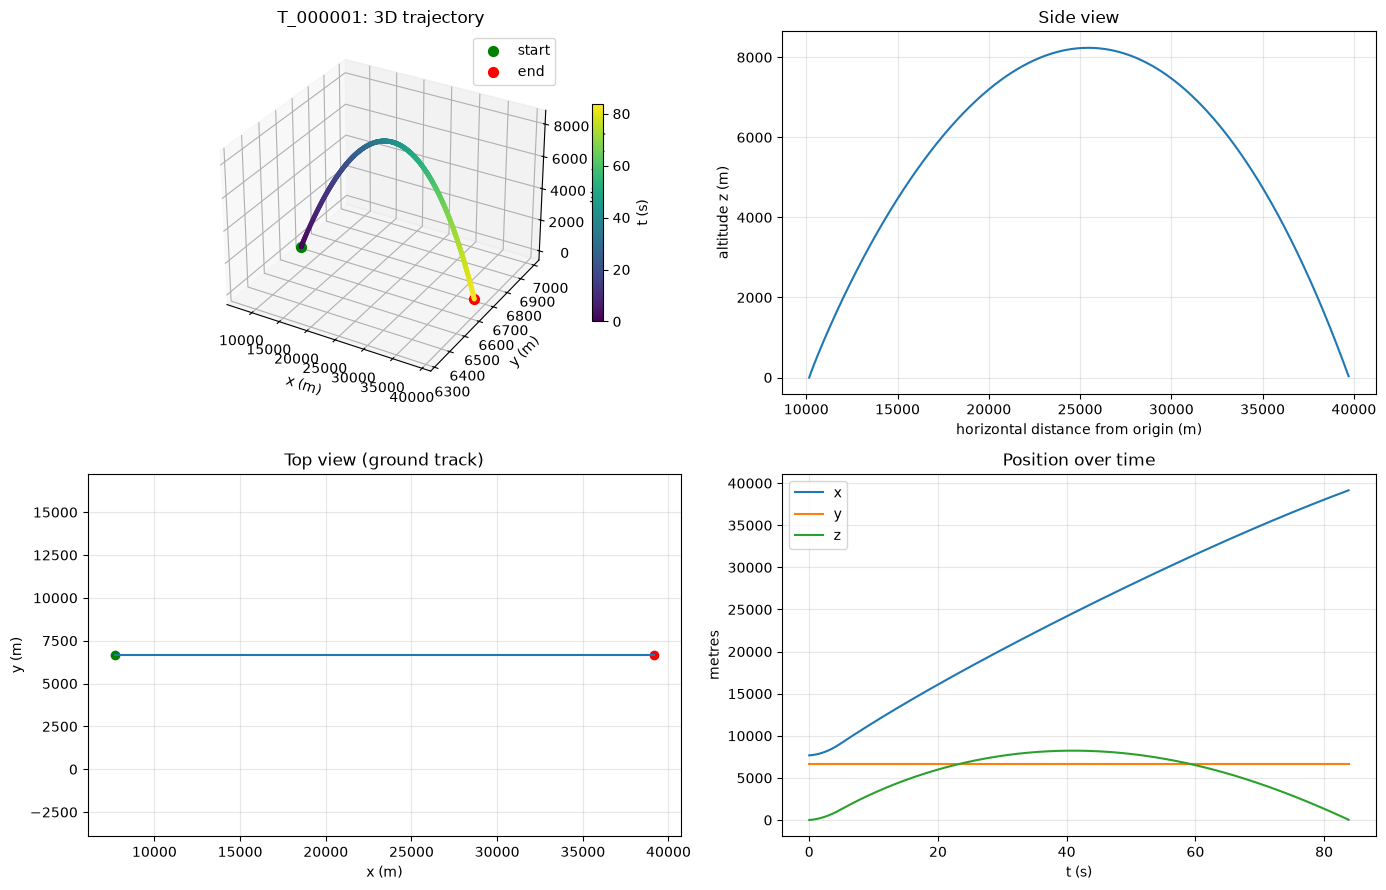

In [16]:
tid = "T_000001"

d = df[df["trajectory_id"] == tid].sort_values("t")
print(len(d), "rows | rocket:", d["is_rocket"].iloc[0],
      "| duration:", round(d["t"].max(), 1), "s")

fig = plt.figure(figsize=(14, 9))

# 3D path, coloured by time
ax = fig.add_subplot(2, 2, 1, projection="3d")
ax.plot(d["x"], d["y"], d["z"], color="lightgray", linewidth=1)
sc = ax.scatter(d["x"], d["y"], d["z"], c=d["t"], cmap="viridis", s=6)
ax.scatter(*d[["x", "y", "z"]].iloc[0], color="green", s=50, label="start")
ax.scatter(*d[["x", "y", "z"]].iloc[-1], color="red", s=50, label="end")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z, altitude (m)")
ax.set_title(f"{tid}: 3D trajectory")
ax.legend()
fig.colorbar(sc, ax=ax, shrink=0.6, label="t (s)")

# Side view: horizontal distance vs altitude
ax2 = fig.add_subplot(2, 2, 2)
ground = (d["x"] ** 2 + d["y"] ** 2) ** 0.5
ax2.plot(ground, d["z"])
ax2.set_xlabel("horizontal distance from origin (m)")
ax2.set_ylabel("altitude z (m)")
ax2.set_title("Side view")
ax2.grid(alpha=0.3)

# Ground track (top view)
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(d["x"], d["y"])
ax3.scatter(d["x"].iloc[0], d["y"].iloc[0], color="green")
ax3.scatter(d["x"].iloc[-1], d["y"].iloc[-1], color="red")
ax3.set_xlabel("x (m)"); ax3.set_ylabel("y (m)")
ax3.set_title("Top view (ground track)")
ax3.set_aspect("equal", adjustable="datalim")
ax3.grid(alpha=0.3)

# Each coordinate against time
ax4 = fig.add_subplot(2, 2, 4)
for c in ["x", "y", "z"]:
    ax4.plot(d["t"], d[c], label=c)
ax4.set_xlabel("t (s)"); ax4.set_ylabel("metres")
ax4.set_title("Position over time")
ax4.legend(); ax4.grid(alpha=0.3)

plt.tight_layout()
plt.show()

end altitude (m):
count    4999.0
mean       16.3
std        11.0
min         0.0
25%         7.3
50%        15.1
75%        23.1
max        71.9
Name: z_end, dtype: float64
is_rocket            False    True 
range_m     count   2564.0   2435.0
            mean   28885.9  27365.4
            std     8596.1  12437.6
            min    12748.5   7187.8
            25%    22273.1  18480.2
            50%    27379.6  24339.7
            75%    34124.8  33382.4
            max    58893.9  95535.1
flight_time count   2564.0   2435.0
            mean      87.8     82.8
            std       23.8     26.4
            min       41.1     41.0
            25%       69.4     61.6
            50%       87.7     80.9
            75%      104.5    100.9
            max      155.7    184.4


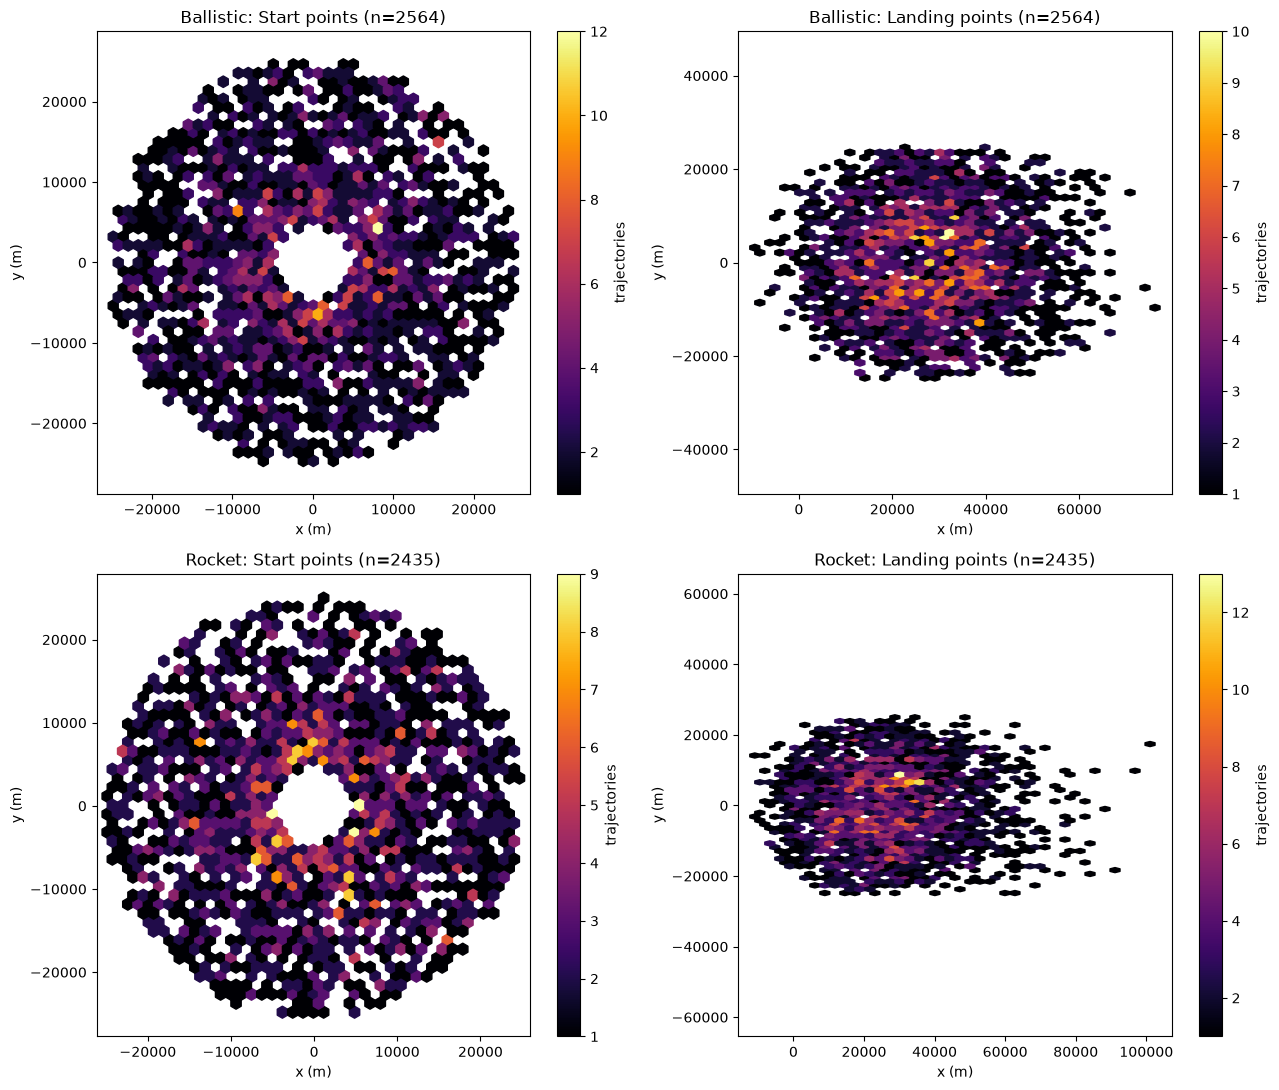

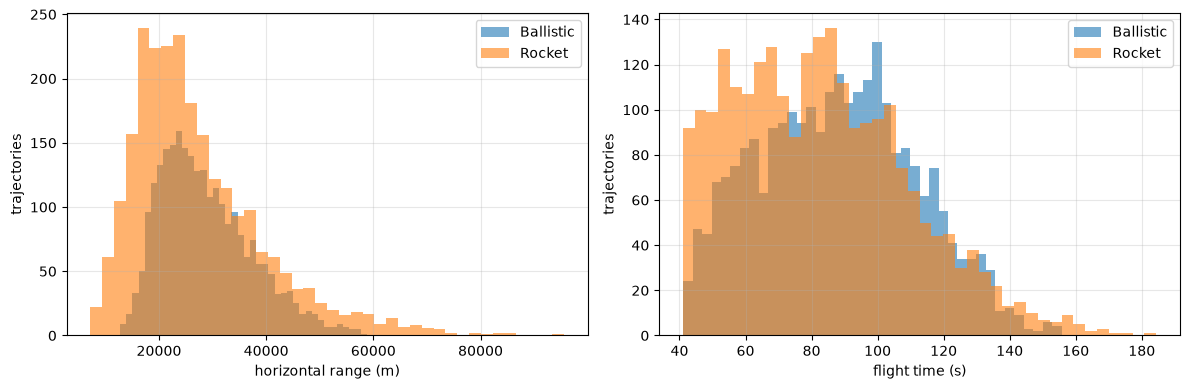

In [4]:
df = df.sort_values(["trajectory_id", "t"])

g = df.groupby("trajectory_id")
start = g.first()[["x", "y", "z", "is_rocket"]]
end = g.last()[["x", "y", "z", "t"]].rename(columns={"t": "flight_time"})
td = start.join(end, lsuffix="_start", rsuffix="_end")
td["range_m"] = np.hypot(td["x_end"] - td["x_start"], td["y_end"] - td["y_start"])

# Sanity check: does the last point actually sit on the ground?
print("end altitude (m):"); print(td["z_end"].describe().round(1))
print(td.groupby("is_rocket")[["range_m", "flight_time"]].describe().round(1).T)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, (label, flag) in enumerate([("Ballistic", False), ("Rocket", True)]):
    s = td[td["is_rocket"] == flag]
    for col, (name, xs, ys) in enumerate([("Start", "x_start", "y_start"),
                                          ("Landing", "x_end", "y_end")]):
        ax = axes[row, col]
        hb = ax.hexbin(s[xs], s[ys], gridsize=40, cmap="inferno", mincnt=1)
        fig.colorbar(hb, ax=ax, label="trajectories")
        ax.set_title(f"{label}: {name} points (n={len(s)})")
        ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
        ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

# Range and flight time by class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for flag, label in [(False, "Ballistic"), (True, "Rocket")]:
    s = td[td["is_rocket"] == flag]
    axes[0].hist(s["range_m"], bins=40, alpha=0.6, label=label)
    axes[1].hist(s["flight_time"], bins=40, alpha=0.6, label=label)
axes[0].set_xlabel("horizontal range (m)"); axes[1].set_xlabel("flight time (s)")
for a in axes:
    a.set_ylabel("trajectories"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
df_radar = pd.read_parquet("/Users/yanbernard/MDMI/data/radar_marks_clean.parquet")
df_radar.head()

,t,x,y,z,vx,vy,vz,v,trajectory_id,is_rocket
0,6.620000,12148.721680,15440.958008,1756.305420,515.329834,0.0,220.316391,560.449951,T_000000,False
1,12.620000,15128.077148,15440.958008,2857.908203,479.487732,0.0,148.125214,501.846161,T_000000,False
2,18.620001,17918.978516,15440.958008,3547.228516,451.779327,0.0,82.374855,459.227814,T_000000,False
3,24.620001,20559.003906,15440.958008,3855.327881,428.772858,0.0,20.804382,429.277283,T_000000,False
4,30.620001,23069.656250,15440.958008,3803.677490,408.380615,0.0,-37.645767,410.112091,T_000000,False


7 rows | rocket: True | duration: 73.6 s


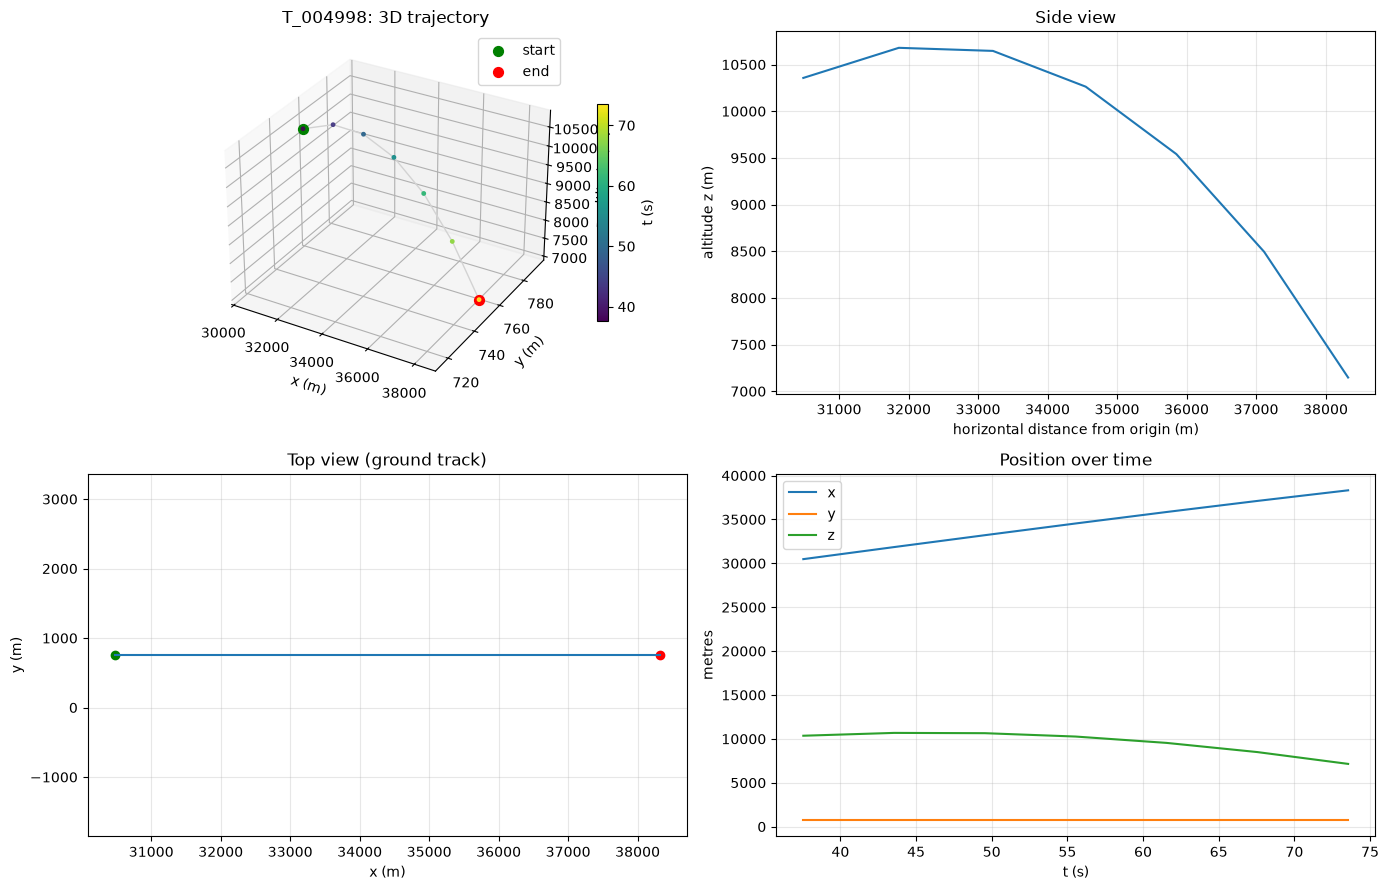

In [6]:
id = "T_000001"

d = df_radar[df_radar["trajectory_id"] == tid].sort_values("t")
print(len(d), "rows | rocket:", d["is_rocket"].iloc[0],
      "| duration:", round(d["t"].max(), 1), "s")

fig = plt.figure(figsize=(14, 9))

# 3D path, coloured by time
ax = fig.add_subplot(2, 2, 1, projection="3d")
ax.plot(d["x"], d["y"], d["z"], color="lightgray", linewidth=1)
sc = ax.scatter(d["x"], d["y"], d["z"], c=d["t"], cmap="viridis", s=6)
ax.scatter(*d[["x", "y", "z"]].iloc[0], color="green", s=50, label="start")
ax.scatter(*d[["x", "y", "z"]].iloc[-1], color="red", s=50, label="end")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z, altitude (m)")
ax.set_title(f"{tid}: 3D trajectory")
ax.legend()
fig.colorbar(sc, ax=ax, shrink=0.6, label="t (s)")

# Side view: horizontal distance vs altitude
ax2 = fig.add_subplot(2, 2, 2)
ground = (d["x"] ** 2 + d["y"] ** 2) ** 0.5
ax2.plot(ground, d["z"])
ax2.set_xlabel("horizontal distance from origin (m)")
ax2.set_ylabel("altitude z (m)")
ax2.set_title("Side view")
ax2.grid(alpha=0.3)

# Ground track (top view)
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(d["x"], d["y"])
ax3.scatter(d["x"].iloc[0], d["y"].iloc[0], color="green")
ax3.scatter(d["x"].iloc[-1], d["y"].iloc[-1], color="red")
ax3.set_xlabel("x (m)"); ax3.set_ylabel("y (m)")
ax3.set_title("Top view (ground track)")
ax3.set_aspect("equal", adjustable="datalim")
ax3.grid(alpha=0.3)

# Each coordinate against time
ax4 = fig.add_subplot(2, 2, 4)
for c in ["x", "y", "z"]:
    ax4.plot(d["t"], d[c], label=c)
ax4.set_xlabel("t (s)"); ax4.set_ylabel("metres")
ax4.set_title("Position over time")
ax4.legend(); ax4.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
num_df = df_radar.select_dtypes(include="number")   
num_df.corr()

,t,x,y,z,vx,vy,vz,v
t,1.000000,0.508825,0.001644,0.403616,-0.429886,NaN,-0.846451,-0.265910
x,0.508825,1.000000,0.011018,0.186833,0.007162,NaN,-0.461743,0.039952
y,0.001644,0.011018,1.000000,-0.010685,0.005939,NaN,-0.005892,0.009658
z,0.403616,0.186833,-0.010685,1.000000,-0.160886,NaN,0.009909,-0.185411
vx,-0.429886,0.007162,0.005939,-0.160886,1.000000,NaN,0.371874,0.863696
vy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vz,-0.846451,-0.461743,-0.005892,0.009909,0.371874,NaN,1.000000,0.357766
v,-0.265910,0.039952,0.009658,-0.185411,0.863696,NaN,0.357766,1.000000


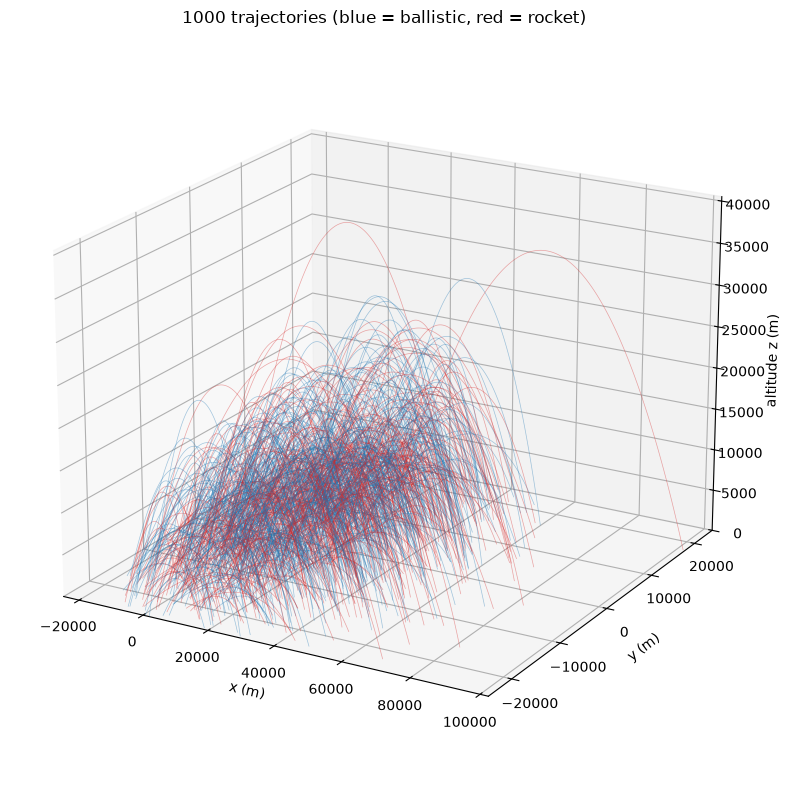

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection


MAX_TRAJ = 1000      # set to None to draw all of them
STEP = 5             # keep every 5th point of each path

ids = df["trajectory_id"].unique()
if MAX_TRAJ and len(ids) > MAX_TRAJ:
    ids = np.random.default_rng(0).choice(ids, MAX_TRAJ, replace=False)

segs, colors = [], []
for tid, d in df[df["trajectory_id"].isin(ids)].groupby("trajectory_id"):
    d = d.iloc[::STEP]
    segs.append(d[["x", "y", "z"]].to_numpy())
    colors.append("tab:red" if d["is_rocket"].iloc[0] else "tab:blue")

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")
ax.add_collection3d(Line3DCollection(segs, colors=colors, linewidths=0.5, alpha=0.4))

# Axis limits are not set automatically for collections
allp = np.vstack(segs)
ax.set_xlim(allp[:, 0].min(), allp[:, 0].max())
ax.set_ylim(allp[:, 1].min(), allp[:, 1].max())
ax.set_zlim(0, allp[:, 2].max())

ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("altitude z (m)")
ax.set_title(f"{len(segs)} trajectories (blue = ballistic, red = rocket)")
ax.view_init(elev=20, azim=-60)
plt.tight_layout()
plt.show()

In [12]:
import numpy as np
import pandas as pd

df
g = df.groupby("trajectory_id")

# How much does y move within each trajectory?
y_range = g["y"].agg(lambda s: s.max() - s.min())
print("y range within a trajectory (m):")
print(y_range.describe().round(3))
print("share of trajectories with y range < 1 m:", round((y_range < 1).mean(), 3))

# Velocity component and the start position
print("\nvy summary:"); print(df["vy"].describe().round(3))
start = g.first()
print("\nstart y across trajectories:"); print(start["y"].describe().round(1))
print("start x across trajectories:"); print(start["x"].describe().round(1))

# Same check on the radar marks (noise will make y wiggle there)
radar = pd.read_parquet("/Users/yanbernard/MDMI/data/radar_marks_noisy.parquet")
print("\nradar y std within a trajectory (m):")
print(radar.groupby("trajectory_id")["y"].std().describe().round(2))

y range within a trajectory (m):
count    4999.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: y, dtype: float64
share of trajectories with y range < 1 m: 1.0

vy summary:
count    4273627.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
Name: vy, dtype: float64

start y across trajectories:
count     4999.0
mean      -162.3
std      11346.4
min     -24811.7
25%      -8614.7
50%       -500.6
75%       8216.0
max      24983.8
Name: y, dtype: float64
start x across trajectories:
count     4999.0
mean      -103.0
std      11324.6
min     -24881.4
25%      -8557.9
50%          5.9
75%       8456.7
max      24931.1
Name: x, dtype: float64

radar y std within a trajectory (m):
count    4999.00
mean       90.96
std        61.45
min         2.75
25%        46.61
50%        74.35
75%       118.68
max       660.34
Name: y, dtype: float64


In [14]:
import pandas as pd

radar = pd.read_parquet("/Users/yanbernard/MDMI/data/radar_marks_clean.parquet")   # <- your radar file

pings = radar.groupby("trajectory_id").size()

print("trajectories:", len(pings))
print("total radar rows:", len(radar))
print("\nPings per trajectory:")
print(pings.value_counts().sort_index())      # how many trajectories have 5, 6, 7... pings
print(pings.describe())

trajectories: 4999
total radar rows: 34993

Pings per trajectory:
7    4999
Name: count, dtype: int64
count    4999.0
mean        7.0
std         0.0
min         7.0
25%         7.0
50%         7.0
75%         7.0
max         7.0
dtype: float64


In [15]:
radar = radar.sort_values(["trajectory_id", "t"])
radar["ping_idx"] = radar.groupby("trajectory_id").cumcount()

print(radar.groupby("ping_idx")["t"].describe().round(2))   # time of 1st, 2nd, ... ping
print(radar.groupby("trajectory_id")["t"].apply(lambda s: s.diff().dropna()).describe().round(3))  # spacing

           count   mean    std   min    25%    50%    75%     max
ping_idx                                                         
0         4999.0  24.73  20.35   0.0   8.36  19.72  36.06  128.29
1         4999.0  30.73  20.35   6.0  14.36  25.72  42.06  134.29
2         4999.0  36.73  20.35  12.0  20.36  31.72  48.06  140.29
3         4999.0  42.73  20.35  18.0  26.36  37.72  54.06  146.29
4         4999.0  48.73  20.35  24.0  32.36  43.72  60.06  152.29
5         4999.0  54.73  20.35  30.0  38.36  49.72  66.06  158.29
6         4999.0  60.73  20.35  36.0  44.36  55.72  72.06  164.29
count    29994.0
mean         6.0
std          0.0
min          6.0
25%          6.0
50%          6.0
75%          6.0
max          6.0
Name: t, dtype: float64


       flight_time  ping_first  ping_last  start_pct  end_pct  dist_pct
count       4999.0      4999.0     4999.0     4999.0   4999.0    4999.0
mean          85.4        24.7       60.7       26.9     73.2      78.6
std           25.2        20.4       20.4       17.7     17.7      16.2
min           41.0         0.0       36.0        0.0     23.8      24.7
25%           65.2         8.4       44.4       11.7     59.4      67.3
50%           84.6        19.7       55.7       24.7     75.7      82.3
75%          102.6        36.1       72.1       40.3     88.2      92.0
max          184.4       128.3      164.3       76.1    100.1     100.0

By class (median):
           flight_time  ping_last    end_pct  dist_pct
is_rocket                                             
False        87.699997  57.400002  74.599998      81.6
True         80.900002  53.500000  76.800003      83.3


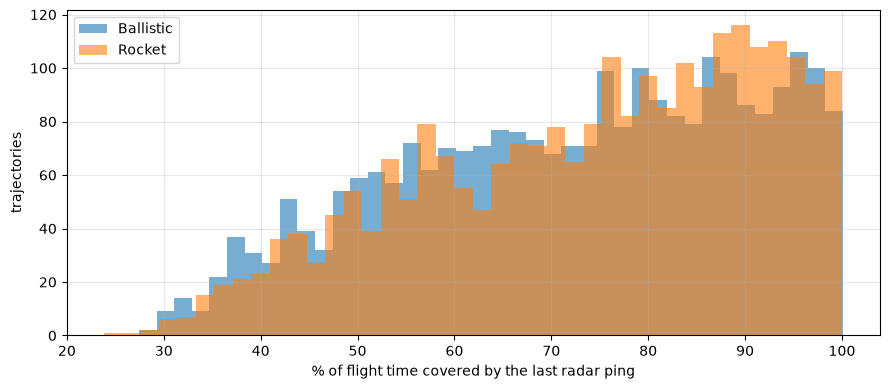

In [19]:
# Full flight: duration, total ground distance, class
g = traj.groupby("trajectory_id")
full = pd.DataFrame({
    "flight_time": g["t"].max(),
    "x_start": g["x"].first(), "x_end": g["x"].last(),
    "is_rocket": g["is_rocket"].first(),
})
full["flight_dist"] = (full["x_end"] - full["x_start"]).abs()   # y is constant, so x is the ground track

# Radar window: first and last ping time
rg = radar.groupby("trajectory_id")["t"]
full["ping_first"] = rg.min()
full["ping_last"] = rg.max()

full["start_pct"] = 100 * full["ping_first"] / full["flight_time"]
full["end_pct"] = 100 * full["ping_last"] / full["flight_time"]
full["remaining_pct"] = 100 - full["end_pct"]

# Share of the ground distance already flown at the last ping (uses the true path at that time)
last_t = full["ping_last"]
x_at_last = {tid: np.interp(last_t[tid], d["t"], d["x"]) for tid, d in traj.groupby("trajectory_id")}
full["dist_pct"] = 100 * (pd.Series(x_at_last) - full["x_start"]).abs() / full["flight_dist"]

print(full[["flight_time", "ping_first", "ping_last", "start_pct", "end_pct", "dist_pct"]]
      .describe().round(1))
print("\nBy class (median):")
print(full.groupby("is_rocket")[["flight_time", "ping_last", "end_pct", "dist_pct"]].median().round(1))

# Histogram: how deep into the flight the radar sees
fig, ax = plt.subplots(figsize=(9, 4))
for flag, label in [(False, "Ballistic"), (True, "Rocket")]:
    ax.hist(full.loc[full["is_rocket"] == flag, "end_pct"], bins=40, alpha=0.6, label=label)
ax.set_xlabel("% of flight time covered by the last radar ping")
ax.set_ylabel("trajectories")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

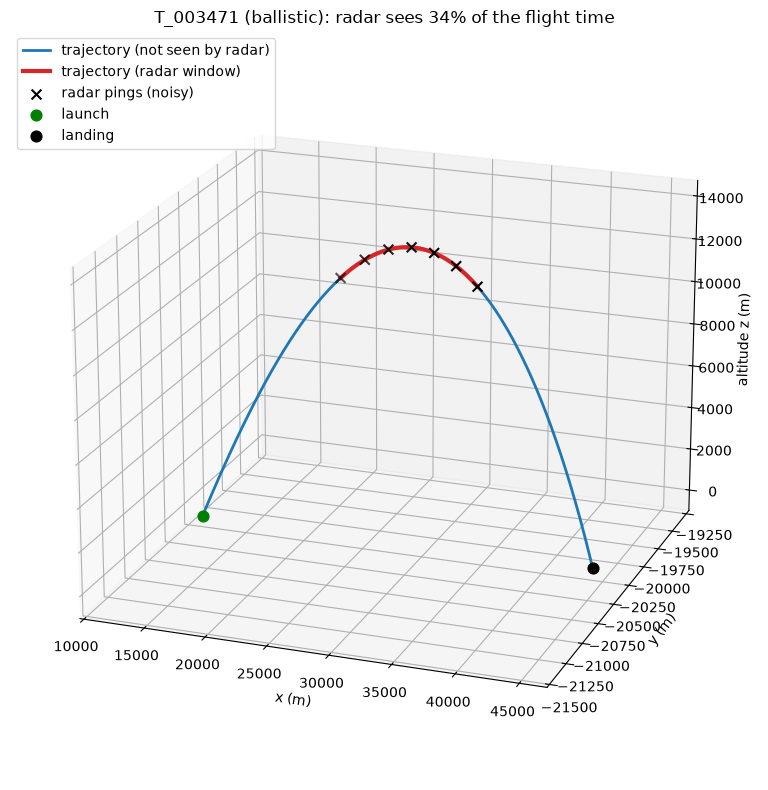

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

radar = pd.read_parquet("/Users/yanbernard/MDMI/data/radar_marks_clean.parquet")       # <- your radar file
traj = pd.read_parquet("/Users/yanbernard/MDMI/data/full_trajectories.parquet")       # or pd.read_csv(...) if the full file is a CSV

rng = np.random.default_rng()                                  # use default_rng(0) for a repeatable pick
tid = rng.choice(radar["trajectory_id"].unique())

f = traj[traj["trajectory_id"] == tid].sort_values("t")
r = radar[radar["trajectory_id"] == tid].sort_values("t")

t0, t1 = r["t"].min(), r["t"].max()
inside = (f["t"] >= t0) & (f["t"] <= t1)
before = f[f["t"] < t0]
radar_part = f[inside]
after = f[f["t"] > t1]

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")

# Blue: true path outside the radar window. Include the end points so the line looks continuous.
if len(before):
    b = pd.concat([before, radar_part.iloc[:1]])
    ax.plot(b["x"], b["y"], b["z"], color="tab:blue", linewidth=2, label="trajectory (not seen by radar)")
if len(after):
    a = pd.concat([radar_part.iloc[-1:], after])
    ax.plot(a["x"], a["y"], a["z"], color="tab:blue", linewidth=2,
            label=None if len(before) else "trajectory (not seen by radar)")

# Red: true path while the radar was observing
ax.plot(radar_part["x"], radar_part["y"], radar_part["z"], color="tab:red", linewidth=3,
        label="trajectory (radar window)")

# Noisy pings
ax.scatter(r["x"], r["y"], r["z"], color="black", marker="x", s=50, label="radar pings (noisy)")

# Start and end of the flight
ax.scatter(*f[["x", "y", "z"]].iloc[0], color="green", s=60, label="launch")
ax.scatter(*f[["x", "y", "z"]].iloc[-1], color="black", s=60, label="landing")

ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("altitude z (m)")
rocket = "rocket" if f["is_rocket"].iloc[0] else "ballistic"
cover = 100 * (t1 - t0) / f["t"].max()
ax.set_title(f"{tid} ({rocket}): radar sees {cover:.0f}% of the flight time")
ax.legend(loc="upper left")
ax.view_init(elev=20, azim=-70)
plt.tight_layout()
plt.show()

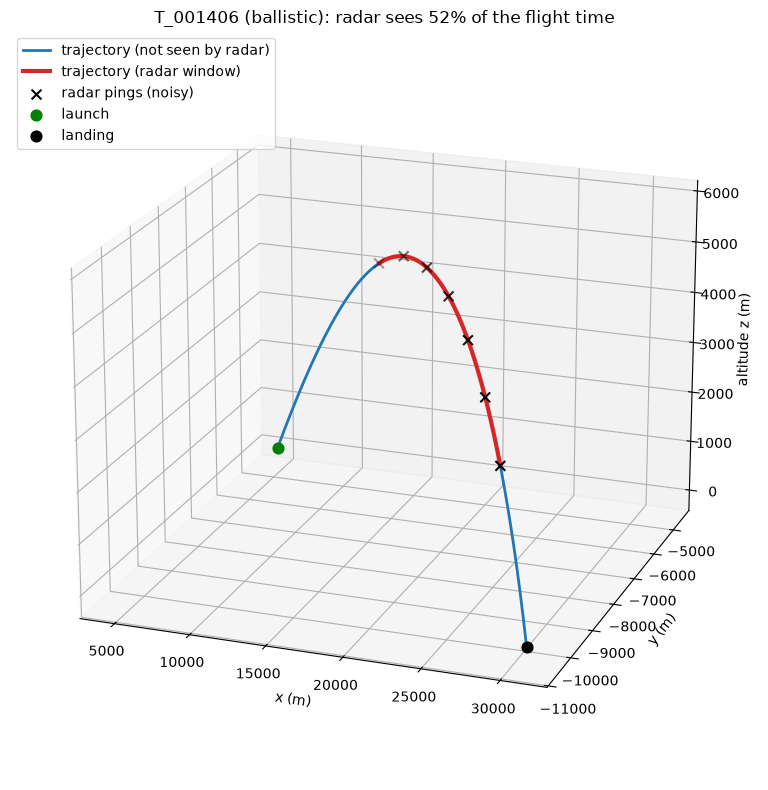

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

radar = pd.read_parquet("/Users/yanbernard/MDMI/data/radar_marks_clean_3d.parquet")       # <- your radar file
traj = pd.read_parquet("/Users/yanbernard/MDMI/data/full_trajectories_3d.parquet")       # or pd.read_csv(...) if the full file is a CSV

rng = np.random.default_rng()                                  # use default_rng(0) for a repeatable pick
tid = rng.choice(radar["trajectory_id"].unique())

f = traj[traj["trajectory_id"] == tid].sort_values("t")
r = radar[radar["trajectory_id"] == tid].sort_values("t")

t0, t1 = r["t"].min(), r["t"].max()
inside = (f["t"] >= t0) & (f["t"] <= t1)
before = f[f["t"] < t0]
radar_part = f[inside]
after = f[f["t"] > t1]

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")

# Blue: true path outside the radar window. Include the end points so the line looks continuous.
if len(before):
    b = pd.concat([before, radar_part.iloc[:1]])
    ax.plot(b["x"], b["y"], b["z"], color="tab:blue", linewidth=2, label="trajectory (not seen by radar)")
if len(after):
    a = pd.concat([radar_part.iloc[-1:], after])
    ax.plot(a["x"], a["y"], a["z"], color="tab:blue", linewidth=2,
            label=None if len(before) else "trajectory (not seen by radar)")

# Red: true path while the radar was observing
ax.plot(radar_part["x"], radar_part["y"], radar_part["z"], color="tab:red", linewidth=3,
        label="trajectory (radar window)")

# Noisy pings
ax.scatter(r["x"], r["y"], r["z"], color="black", marker="x", s=50, label="radar pings (noisy)")

# Start and end of the flight
ax.scatter(*f[["x", "y", "z"]].iloc[0], color="green", s=60, label="launch")
ax.scatter(*f[["x", "y", "z"]].iloc[-1], color="black", s=60, label="landing")

ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("altitude z (m)")
rocket = "rocket" if f["is_rocket"].iloc[0] else "ballistic"
cover = 100 * (t1 - t0) / f["t"].max()
ax.set_title(f"{tid} ({rocket}): radar sees {cover:.0f}% of the flight time")
ax.legend(loc="upper left")
ax.view_init(elev=20, azim=-70)
plt.tight_layout()
plt.show()